# Group Assignment 2 — Problem 1


## Part A —  Bayesian Network


In [1]:
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261020
SAMPLE_SIZES = [500, 5000, 20000]
STATES = {'W':['Hot','Mild','Cold'], 'D':['Weekday','Weekend'], 'O':['High','Low'], 'A':['On','Off'], 'L':['Heavy','Light'], 'E':['High','Low']}
PARENTS = {'W':[], 'D':[], 'O':['D'], 'A':['W','O'], 'L':['O'], 'E':['A','L']}
CPT_EXPERT = {
 'W': {(): {'Hot':0.50,'Mild':0.30,'Cold':0.20}},
 'D': {(): {'Weekday':0.70,'Weekend':0.30}},
 'O': {('Weekday',):{'High':0.45,'Low':0.55}, ('Weekend',):{'High':0.80,'Low':0.20}},
 'A': {('Hot','High'):{'On':0.90,'Off':0.10}, ('Hot','Low'):{'On':0.60,'Off':0.40}, ('Mild','High'):{'On':0.40,'Off':0.60}, ('Mild','Low'):{'On':0.15,'Off':0.85}, ('Cold','High'):{'On':0.10,'Off':0.90}, ('Cold','Low'):{'On':0.05,'Off':0.95}},
 'L': {('High',):{'Heavy':0.75,'Light':0.25}, ('Low',):{'Heavy':0.35,'Light':0.65}},
 'E': {('On','Heavy'):{'High':0.92,'Low':0.08}, ('On','Light'):{'High':0.68,'Low':0.32}, ('Off','Heavy'):{'High':0.55,'Low':0.45}, ('Off','Light'):{'High':0.12,'Low':0.88}}
}
TOPO_ORDER = ['W','D','O','A','L','E']

def p_state(cpt, var, state, assignment):
    return cpt[var][tuple(assignment[p] for p in PARENTS[var])][state]

def joint_probability(assignment, cpt=CPT_EXPERT):
    result = 1.0
    for var in TOPO_ORDER:
        result *= p_state(cpt, var, assignment[var], assignment)
    return result

def all_assignments():
    for values in product(*(STATES[v] for v in TOPO_ORDER)):
        yield dict(zip(TOPO_ORDER, values))

def query_probability(query, evidence=None, cpt=CPT_EXPERT):
    evidence = evidence or {}
    numerator = denominator = 0.0
    for a in all_assignments():
        if any(a[k] != v for k,v in evidence.items()):
            continue
        p = joint_probability(a, cpt)
        denominator += p
        if all(a[k] == v for k,v in query.items()):
            numerator += p
    if denominator == 0:
        raise ZeroDivisionError('Evidence has zero probability')
    return numerator / denominator

def validate_cpts(cpt=CPT_EXPERT, tol=1e-12):
    rows=[]
    for var, table in cpt.items():
        for cfg, dist in table.items():
            total=sum(dist.values())
            valid=all(0 <= p <= 1 for p in dist.values())
            rows.append({'Variable':var,'Parent configuration':str(cfg),'Row sum':total,'Valid probabilities':valid,'Pass':abs(total-1)<=tol and valid})
            assert valid and abs(total-1)<=tol, f'Invalid CPT row: {var}, {cfg}'
    return pd.DataFrame(rows)

cpt_check = validate_cpts()
display(cpt_check)
assert cpt_check['Pass'].all()
print('All CPT rows are valid and sum to 1.')

,Variable,Parent configuration,Row sum,Valid probabilities,Pass
0,W,(),1.0,True,True
1,D,(),1.0,True,True
2,O,"('Weekday',)",1.0,True,True
3,O,"('Weekend',)",1.0,True,True
4,A,"('Hot', 'High')",1.0,True,True
5,A,"('Hot', 'Low')",1.0,True,True
6,A,"('Mild', 'High')",1.0,True,True
7,A,"('Mild', 'Low')",1.0,True,True
8,A,"('Cold', 'High')",1.0,True,True
9,A,"('Cold', 'Low')",1.0,True,True


All CPT rows are valid and sum to 1.


### Network visualization
The arrows represent direct dependencies, not guaranteed deterministic effects.

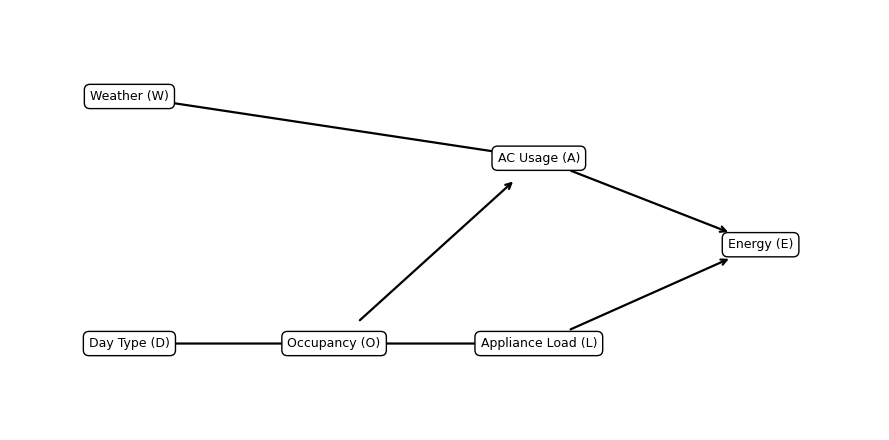

In [2]:
pos={'W':(0,2),'D':(0,0),'O':(1.2,0),'A':(2.4,1.5),'L':(2.4,0),'E':(3.7,0.8)}
edges=[('W','A'),('D','O'),('O','A'),('O','L'),('A','E'),('L','E')]
labels={'W':'Weather (W)','D':'Day Type (D)','O':'Occupancy (O)','A':'AC Usage (A)','L':'Appliance Load (L)','E':'Energy (E)'}
fig, ax=plt.subplots(figsize=(9,4.5))
for u,v in edges:
    ax.annotate('', xy=pos[v], xytext=pos[u], arrowprops=dict(arrowstyle='->',lw=1.6,shrinkA=25,shrinkB=25))
for node,(x,y) in pos.items():
    ax.text(x,y,labels[node],ha='center',va='center',bbox=dict(boxstyle='round,pad=.45',fc='white',ec='black'),fontsize=9)
ax.set_xlim(-.7,4.4); ax.set_ylim(-.7,2.7); ax.axis('off'); plt.tight_layout(); plt.show()

###  inference for Q1–Q7
 inference sums the joint probability over all complete assignments compatible with the evidence. The full state space contains `3 × 2 × 2 × 2 × 2 × 2 = 96` assignments.

In [3]:
def query_set(cpt=CPT_EXPERT):
    queries=[('Q1',{'E':'High'},{}),('Q2',{'E':'High'},{'W':'Hot'}),('Q3',{'E':'High'},{'D':'Weekend'}),('Q4',{'E':'High'},{'W':'Cold','O':'High'}),('Q5',{'W':'Hot'},{'E':'High'}),('Q6',{'A':'On'},{'E':'High'}),('Q7',{'A':'On'},{'E':'High','L':'Heavy'})]
    return {name:query_probability(q,e,cpt) for name,q,e in queries}

expert_queries=query_set()
display(pd.DataFrame({'Query':expert_queries.keys(),'Probability':expert_queries.values(),'Percent':[100*x for x in expert_queries.values()]}))

,Query,Probability,Percent
0,Q1,0.580631,58.063104
1,Q2,0.706266,70.626575
2,Q3,0.640199,64.019850
3,Q4,0.484250,48.425000
4,Q5,0.608188,60.818808
5,Q6,0.692867,69.286668
6,Q7,0.649899,64.989930


### Q1 hand calculation (summation proof)
The network factorization is

\[
P(W,D,O,A,L,E)=P(W)P(D)P(O\mid D)P(A\mid W,O)P(L\mid O)P(E\mid A,L).
\]

Therefore

\[
P(E=H)=\sum_{w,d,o,a,l}P(w)P(d)P(o\mid d)P(a\mid w,o)P(l\mid o)P(E=H\mid a,l).
\]

For each weather/occupancy pair, sum over AC and load first. These conditional results follow from the four AC/load combinations in the energy CPT.

In [4]:
def p_energy_given_weather_occupancy(w,o):
    total=0.0
    for a in STATES['A']:
        pa=CPT_EXPERT['A'][(w,o)][a]
        for l in STATES['L']:
            pl=CPT_EXPERT['L'][(o,)][l]
            pe=CPT_EXPERT['E'][(a,l)]['High']
            total += pa*pl*pe
    return total

weather_p={'Hot':.50,'Mild':.30,'Cold':.20}
occupancy_p={'High':.555,'Low':.445}  # marginal occupancy; derived from weekday/weekend
rows=[]
for w in STATES['W']:
    for o in STATES['O']:
        cond=p_energy_given_weather_occupancy(w,o)
        weight=weather_p[w]*occupancy_p[o]
        rows.append({'Weather':w,'Occupancy':o,'P(W)':weather_p[w],'P(O)':occupancy_p[o], 'P(E=High|W,O)':cond,'Contribution':weight*cond})
hand=pd.DataFrame(rows)
display(hand)
print('Q1 = sum of contributions =', hand['Contribution'].sum())
print('Q1 from exact inference =', expert_queries['Q1'])
assert abs(hand['Contribution'].sum()-expert_queries['Q1']) < 1e-12

,Weather,Occupancy,P(W),P(O),"P(E=High|W,O)",Contribution
0,Hot,High,0.5,0.555,0.818250,0.227064
1,Hot,Low,0.5,0.445,0.566600,0.126069
2,Mild,High,0.3,0.555,0.609500,0.101482
3,Mild,Low,0.3,0.445,0.344525,0.045994
4,Cold,High,0.2,0.555,0.484250,0.053752
5,Cold,Low,0.2,0.445,0.295175,0.026271


Q1 = sum of contributions = 0.5806310375
Q1 from exact inference = 0.5806310375000002


## Part B — Conditional independence and d-separation
A path is blocked by a conditioned non-collider, while conditioning on a collider (or its descendant) can open a path. We check each assignment statement with numerical probabilities.

In [5]:
def independence_checks(cpt=CPT_EXPERT):
    results=[]
    p1=query_probability({'W':'Hot'}, {}, cpt)
    p2=query_probability({'W':'Hot'}, {'D':'Weekend'}, cpt)
    results.append({'Statement':'W ⟂ D','P1':p1,'P2':p2,'Equal within tolerance':abs(p1-p2)<1e-10,'Conclusion':'Holds; W and D are disconnected roots.'})
    p1=query_probability({'W':'Hot'}, {'E':'High'}, cpt)
    p2=query_probability({'W':'Hot'}, {'E':'High','D':'Weekend'}, cpt)
    results.append({'Statement':'W ⟂ D | E','P1':p1,'P2':p2,'Equal within tolerance':abs(p1-p2)<1e-10,'Conclusion':'Does not hold; conditioning on collider E opens W→A→E←L←O←D.'})
    p1=query_probability({'W':'Hot'}, {'O':'High'}, cpt)
    p2=query_probability({'W':'Hot'}, {'O':'High','L':'Heavy'}, cpt)
    results.append({'Statement':'W ⟂ L | O','P1':p1,'P2':p2,'Equal within tolerance':abs(p1-p2)<1e-10,'Conclusion':'Holds; conditioning on O blocks the non-collider path W→A←O→L; the collider at A is not conditioned on, and path via E is blocked at collider E unless E/descendant observed.'})
    return pd.DataFrame(results)

independence_results=independence_checks()
display(independence_results)

,Statement,P1,P2,Equal within tolerance,Conclusion
0,W ⟂ D,0.500000,0.500000,True,Holds; W and D are disconnected roots.
1,W ⟂ D | E,0.608188,0.599751,False,Does not hold; conditioning on collider E open...
2,W ⟂ L | O,0.500000,0.500000,True,Holds; conditioning on O blocks the non-collid...


## Part C — Synthetic data by ancestral sampling
Sample nodes in topological order: Weather and DayType first; Occupancy given DayType; AC given Weather and Occupancy; Load given Occupancy; Energy given AC and Load. A fixed seed makes results reproducible.

In [6]:
def draw_state(states, probs, rng):
    return states[int(rng.choice(len(states), p=np.asarray(probs,dtype=float)))]

def ancestral_sample(n, seed, cpt=CPT_EXPERT):
    rng=np.random.default_rng(seed); rows=[]
    for _ in range(n):
        a={}
        a['W']=draw_state(STATES['W'],[cpt['W'][()][s] for s in STATES['W']],rng)
        a['D']=draw_state(STATES['D'],[cpt['D'][()][s] for s in STATES['D']],rng)
        a['O']=draw_state(STATES['O'],[cpt['O'][(a['D'],)][s] for s in STATES['O']],rng)
        a['A']=draw_state(STATES['A'],[cpt['A'][(a['W'],a['O'])][s] for s in STATES['A']],rng)
        a['L']=draw_state(STATES['L'],[cpt['L'][(a['O'],)][s] for s in STATES['L']],rng)
        a['E']=draw_state(STATES['E'],[cpt['E'][(a['A'],a['L'])][s] for s in STATES['E']],rng)
        rows.append(a)
    return pd.DataFrame(rows,columns=TOPO_ORDER)

seed_sequence=np.random.SeedSequence(SEED)
child_seeds=[int(s.generate_state(1)[0]) for s in seed_sequence.spawn(3)]
datasets={n:ancestral_sample(n,seed) for n,seed in zip(SAMPLE_SIZES,child_seeds)}
for n,df in datasets.items():
    print(f'\nDataset size: {n}')
    display(df['W'].value_counts().reindex(STATES['W'],fill_value=0).rename('Count').to_frame().assign(Frequency=lambda x:x['Count']/n))
    print('(Weather, Occupancy) counts')
    display(pd.crosstab(df['W'],df['O']).reindex(index=STATES['W'],columns=STATES['O'],fill_value=0))


Dataset size: 500


,Count,Frequency
W,,
Hot,245,0.490
Mild,148,0.296
Cold,107,0.214


(Weather, Occupancy) counts


O,High,Low
W,,
Hot,138,107
Mild,78,70
Cold,57,50



Dataset size: 5000


,Count,Frequency
W,,
Hot,2529,0.5058
Mild,1542,0.3084
Cold,929,0.1858


... (2 outputs left out)


Dataset size: 20000


,Count,Frequency
W,,
Hot,10028,0.5014
Mild,5970,0.2985
Cold,4002,0.2001


(Weather, Occupancy) counts


O,High,Low
W,,
Hot,5558,4470
Mild,3297,2673
Cold,2240,1762


## Part D — Parameter learning (MLE and BDeu, ESS = 10)
For MLE, each CPT probability is a conditional relative frequency. For Bayesian estimation, use a symmetric Dirichlet prior with equivalent sample size (ESS) 10: for a node with `r` child states and `q` parent configurations, each cell receives prior count `ESS/(q*r)`. The network structure is held fixed as required.

In [7]:
def estimate_cpt(data, method='MLE', ess=10.0):
    learned={}
    for var in TOPO_ORDER:
        parents=PARENTS[var]
        configs=list(product(*(STATES[p] for p in parents))) if parents else [()]
        r=len(STATES[var]); q=len(configs); learned[var]={}
        for cfg in configs:
            if parents:
                mask=np.ones(len(data),dtype=bool)
                for p,val in zip(parents,cfg): mask &= (data[p].to_numpy()==val)
                subset=data.loc[mask,var]
            else: subset=data[var]
            counts=np.array([(subset==s).sum() for s in STATES[var]],dtype=float)
            if method.upper()=='MLE':
                probs=counts/counts.sum() if counts.sum()>0 else np.full(r,1/r)
            elif method.upper() in ('BAYES','BAYESIAN','BDEU'):
                alpha=ess/(q*r)
                probs=(counts+alpha)/(counts.sum()+r*alpha)
            else: raise ValueError('method must be MLE or BDeu')
            learned[var][tuple(cfg)]=dict(zip(STATES[var],probs.tolist()))
    return learned

# Expert AC CPT displayed alongside learned CPTs for each data size.
ac_rows=[]; comparison_rows=[]; mean_error_rows=[]
for n,df in datasets.items():
    mle=estimate_cpt(df,'MLE')
    bayes=estimate_cpt(df,'BDeu',ess=10)
    for cfg,dist in CPT_EXPERT['A'].items():
        ac_rows.append({'N':n,'Weather':cfg[0],'Occupancy':cfg[1], 'Expert P(On)':dist['On'], 'MLE P(On)':mle['A'][cfg]['On'], 'Bayesian P(On)':bayes['A'][cfg]['On']})
    eq=query_set(CPT_EXPERT); mq=query_set(mle); bq=query_set(bayes)
    for q in eq:
        comparison_rows.append({'N':n,'Query':q,'Expert':eq[q],'MLE':mq[q],'Bayesian (BDeu ESS=10)':bq[q], '|Diff| MLE':abs(mq[q]-eq[q]), '|Diff| Bayesian':abs(bq[q]-eq[q])})
    this=pd.DataFrame([r for r in comparison_rows if r['N']==n])
    mean_error_rows.append({'N':n,'Mean absolute difference MLE':this['|Diff| MLE'].mean(),'Mean absolute difference Bayesian':this['|Diff| Bayesian'].mean()})

ac_cpt_comparison=pd.DataFrame(ac_rows)
query_comparison=pd.DataFrame(comparison_rows)
mean_errors=pd.DataFrame(mean_error_rows)
display(ac_cpt_comparison)


,N,Weather,Occupancy,Expert P(On),MLE P(On),Bayesian P(On)
0,500,Hot,High,0.90,0.913043,0.908115
1,500,Hot,Low,0.60,0.635514,0.633436
2,500,Mild,High,0.40,0.423077,0.424686
3,500,Mild,Low,0.15,0.185714,0.193023
4,500,Cold,High,0.10,0.070175,0.082386
5,500,Cold,Low,0.05,0.040000,0.054839
6,5000,Hot,High,0.90,0.909480,0.908994
7,5000,Hot,Low,0.60,0.574600,0.574490
8,5000,Mild,High,0.40,0.377183,0.377421
9,5000,Mild,Low,0.15,0.153734,0.154576


## Part E — Comparative analysis
The table below compares the expert inference results with each learned model. Absolute difference is `abs(learned query - expert query)`. Repeat for each requested dataset size.


Comparison for N=500


,N,Query,Expert,MLE,Bayesian (BDeu ESS=10),|Diff| MLE,|Diff| Bayesian
0,500,Q1,0.580631,0.584757,0.583140,0.004125,0.002509
1,500,Q2,0.706266,0.712893,0.707204,0.006627,0.000938
2,500,Q3,0.640199,0.639853,0.634473,0.000346,0.005726
3,500,Q4,0.484250,0.489692,0.492709,0.005442,0.008459
4,500,Q5,0.608188,0.597373,0.590522,0.010815,0.017666
5,500,Q6,0.692867,0.691180,0.687720,0.001687,0.005147
6,500,Q7,0.649899,0.644016,0.641694,0.005884,0.008205



Comparison for N=5000


,N,Query,Expert,MLE,Bayesian (BDeu ESS=10),|Diff| MLE,|Diff| Bayesian
0,5000,Q1,0.580631,0.569606,0.569472,0.011026,0.011159
1,5000,Q2,0.706266,0.692474,0.691937,0.013792,0.014328
2,5000,Q3,0.640199,0.625833,0.625280,0.014365,0.014918
3,5000,Q4,0.484250,0.466035,0.466489,0.018215,0.017761
4,5000,Q5,0.608188,0.614905,0.614154,0.006717,0.005966
5,5000,Q6,0.692867,0.695568,0.695187,0.002701,0.002320
6,5000,Q7,0.649899,0.659779,0.659503,0.009880,0.009604



Comparison for N=20000


,N,Query,Expert,MLE,Bayesian (BDeu ESS=10),|Diff| MLE,|Diff| Bayesian
0,20000,Q1,0.580631,0.581473,0.581434,0.000842,0.000803
1,20000,Q2,0.706266,0.707385,0.707243,0.001120,0.000977
2,20000,Q3,0.640199,0.642355,0.642201,0.002156,0.002003
3,20000,Q4,0.484250,0.489712,0.489796,0.005462,0.005546
4,20000,Q5,0.608188,0.609974,0.609789,0.001785,0.001601
5,20000,Q6,0.692867,0.695690,0.695596,0.002823,0.002729
6,20000,Q7,0.649899,0.653073,0.653006,0.003173,0.003107


Mean absolute differences over Q1-Q7


,N,Mean absolute difference MLE,Mean absolute difference Bayesian
0,500,0.004989,0.006950
1,5000,0.010957,0.010865
2,20000,0.002480,0.002395


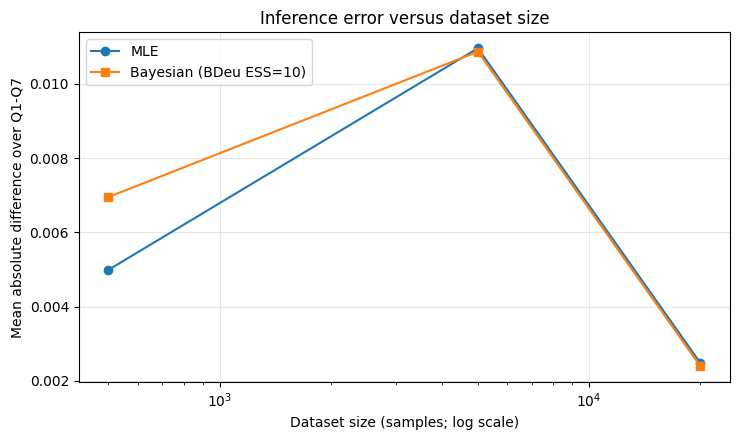

Largest error at N=500 (MLE):


,N,Query,Expert,MLE,Bayesian (BDeu ESS=10),|Diff| MLE,|Diff| Bayesian
4,500,Q5,0.608188,0.597373,0.590522,0.010815,0.017666


Largest error at N=500 (Bayesian):


,N,Query,Expert,MLE,Bayesian (BDeu ESS=10),|Diff| MLE,|Diff| Bayesian
4,500,Q5,0.608188,0.597373,0.590522,0.010815,0.017666


In [8]:
for n in SAMPLE_SIZES:
    print(f'\nComparison for N={n}')
    display(query_comparison[query_comparison['N']==n].reset_index(drop=True))
print('Mean absolute differences over Q1-Q7')
display(mean_errors)

fig,ax=plt.subplots(figsize=(7.5,4.5))
ax.plot(mean_errors['N'],mean_errors['Mean absolute difference MLE'],marker='o',label='MLE')
ax.plot(mean_errors['N'],mean_errors['Mean absolute difference Bayesian'],marker='s',label='Bayesian (BDeu ESS=10)')
ax.set_xscale('log'); ax.set_xlabel('Dataset size (samples; log scale)'); ax.set_ylabel('Mean absolute difference over Q1-Q7'); ax.set_title('Inference error versus dataset size'); ax.grid(True,alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

small=query_comparison[query_comparison['N']==500]
print('Largest error at N=500 (MLE):')
display(small.loc[[small['|Diff| MLE'].idxmax()]])
print('Largest error at N=500 (Bayesian):')
display(small.loc[[small['|Diff| Bayesian'].idxmax()]])

- **Explaining away (Q6 vs Q7):** Q6 conditions only on High energy; Q7 additionally observes Heavy load. Heavy load is an alternative cause of High energy, so the posterior probability that AC is On decreases when Heavy load is known.


- **Small-data estimator:** For this fixed seed, at N=500 the MLE mean absolute difference is 0.004989 and BDeu is 0.006950, so MLE performs better on the seven-query average in this particular run. At N=5000, BDeu is slightly better (0.010865 vs 0.010957); at N=20000, BDeu is slightly better (0.002395 vs 0.002480). This is not a universal result: BDeu smoothing reduces extreme small-count estimates but can add bias, while MLE can have higher variance. Independent finite samples can also make errors non-monotonic across the three dataset sizes.
- **Largest error at N=500:** the code prints the largest query error separately for MLE and BDeu. A query conditioned on relatively rare evidence can be unstable because only a small subset of samples contributes to its estimate.